In [19]:
import pretty_midi
import numpy as np
import scipy.io.wavfile

def generate_piano_scale_midi(output_file="piano_scale.mid"):
    # Create a PrettyMIDI object
    midi = pretty_midi.PrettyMIDI()
    
    # Create an Instrument instance (Acoustic Grand Piano)
    piano = pretty_midi.Instrument(program=pretty_midi.instrument_name_to_program("Acoustic Grand Piano"))
    
    # Define start time and duration for each note
    start_time = 0.0
    duration = 0.5  # Half second per note
    
    # Generate notes from MIDI 21 (A0) to MIDI 108 (C8)
    for note_number in range(21, 109):
        note = pretty_midi.Note(velocity=100, pitch=note_number, start=start_time, end=start_time + duration)
        piano.notes.append(note)
        start_time += duration  # Increment start time for the next note
    
    # Add the instrument to the PrettyMIDI object
    midi.instruments.append(piano)
    
    # Write out the MIDI data to a file
    midi.write(output_file)
    print(f"MIDI file saved as {output_file}")

# Generate the piano scale MIDI file and synthesize it
generate_piano_scale_midi()

MIDI file saved as piano_scale.mid


(89, 3781)
(1025, 3781)


Text(0.5, 1.0, 'Piano Roll Aligned with STFT')

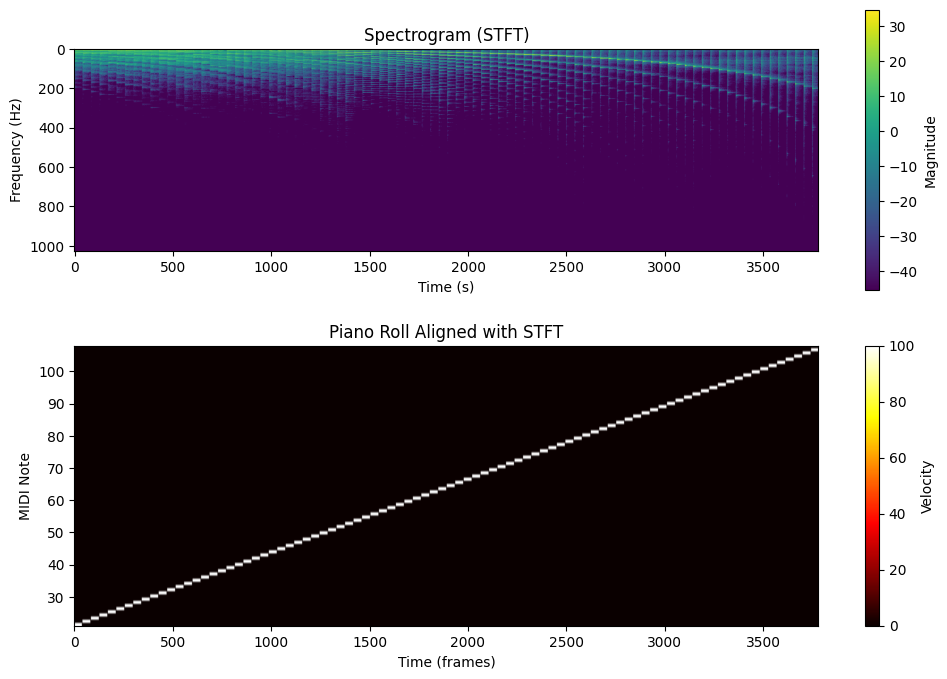

In [17]:
import pretty_midi
import librosa
import numpy as np
import matplotlib.pyplot as plt

midi_file = "piano_scale.mid"
midi = pretty_midi.PrettyMIDI(midi_file)
piano_roll = midi.get_piano_roll(fs=fs // 512)  # Match time resolution with STFT hop size
piano_roll = piano_roll[21:110, :]  # Exclude notes below MIDI note 21 (A0)
print(piano_roll.shape)

x, fs = librosa.load("piano_scale.wav", sr=None)
X = librosa.stft(x, n_fft=2048, hop_length=512)
Zxx = np.abs(X[:,:piano_roll.shape[1]])
print(Zxx.shape)
    
# Plot STFT and piano roll
plt.figure(figsize=(12, 8))

# Plot STFT
plt.subplot(2, 1, 1)
plt.imshow(librosa.amplitude_to_db(Zxx))
plt.colorbar(label='Magnitude')
plt.xlabel("Time (s)")
plt.ylabel("Frequency (Hz)")
plt.title("Spectrogram (STFT)")

# Plot piano roll
plt.subplot(2, 1, 2)
plt.imshow(piano_roll, aspect='auto', cmap='hot', origin='lower', extent=[0, piano_roll.shape[1], 21, 108])
plt.colorbar(label='Velocity')
plt.xlabel("Time (frames)")
plt.ylabel("MIDI Note")
plt.title("Piano Roll Aligned with STFT")



In [18]:
epsilon = 1e-10 # error to introduce
V = Zxx + epsilon
K, N = np.shape(V)
S = 89 
print(f"S = {S} : Number of notes")

S = 89 : Number of notes


In [19]:
def divergence(V,W,H, beta = 2):
    
    """
    beta = 2 : Euclidean cost function
    beta = 1 : Kullback-Leibler cost function
    beta = 0 : Itakura-Saito cost function
    """ 
    
    if beta == 0 : return np.sum( V/(W@H+epsilon) - np.log10(V/(W@H+epsilon)) -1 )
    
    if beta == 1 : return np.sum( V*np.log10(V/(W@H+epsilon)) + (W@H - V))
    
    if beta == 2 : return 1/2*np.linalg.norm(W@H-V)

  0%|          | 0/100 [00:00<?, ?it/s]

Iteration 0 : Divergence = 237.23044000719247


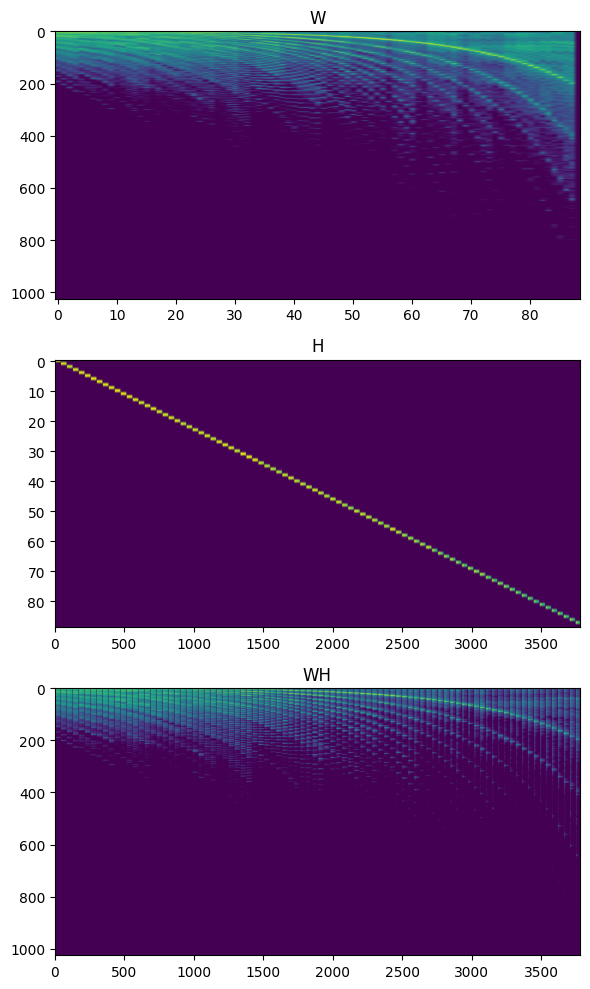

  1%|          | 1/100 [00:01<02:04,  1.26s/it]

Iteration 1 : Divergence = 191.61191099303574


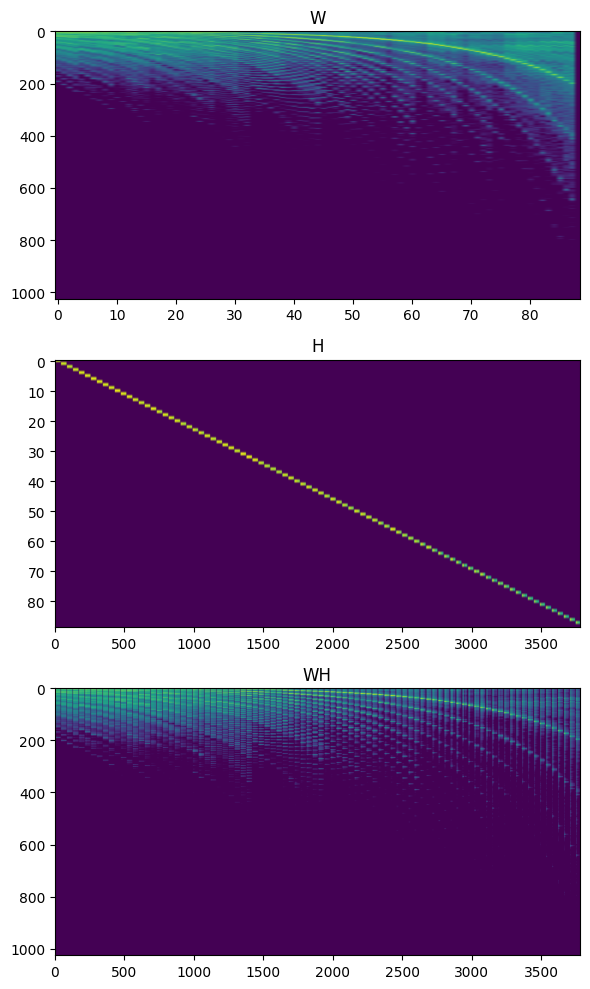

  2%|▏         | 2/100 [00:02<01:59,  1.22s/it]

Iteration 2 : Divergence = 191.58544600342475


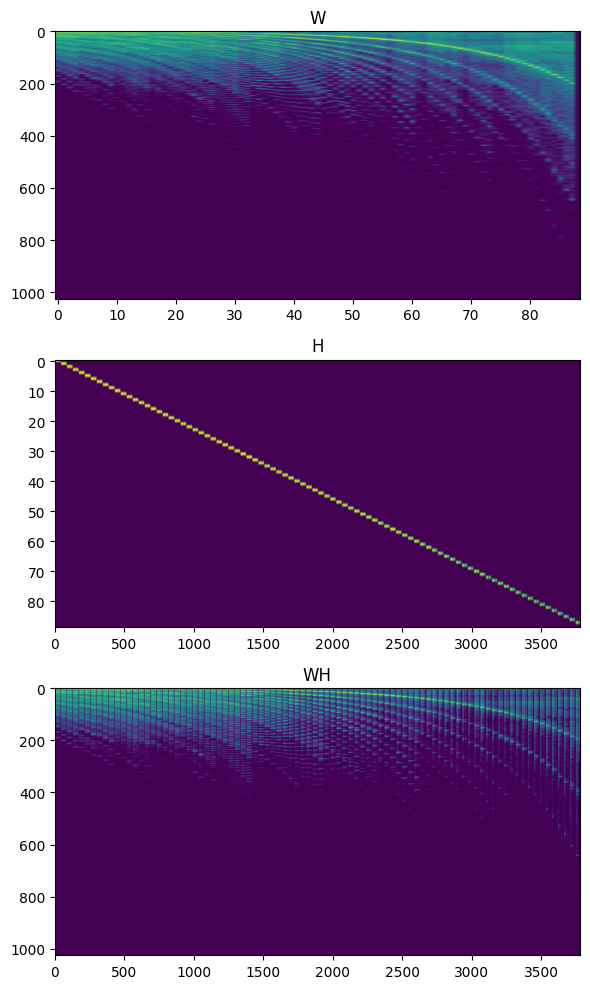

  3%|▎         | 3/100 [00:03<02:00,  1.24s/it]

Iteration 3 : Divergence = 191.58535584532214


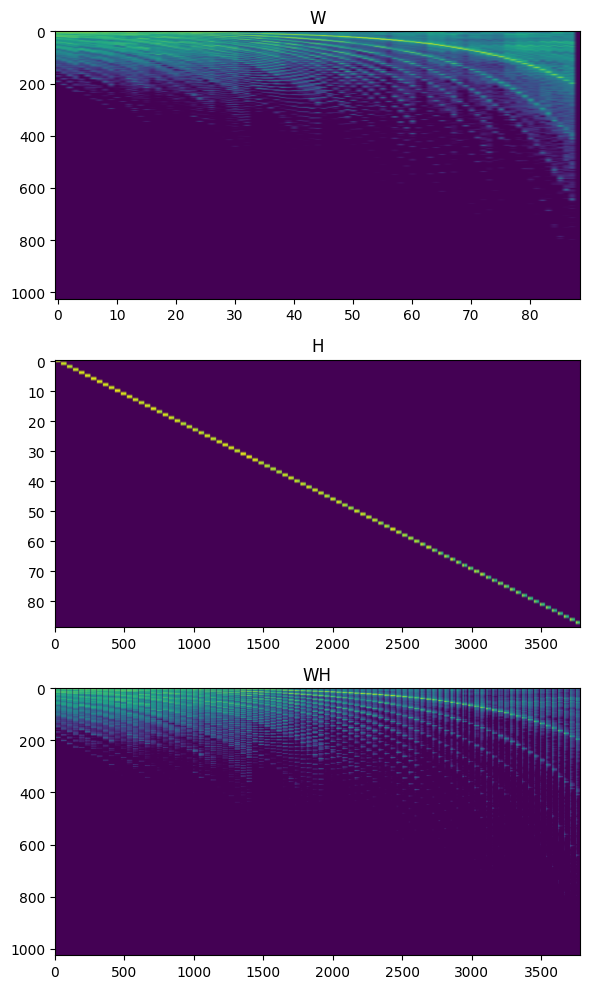

  4%|▍         | 4/100 [00:04<01:59,  1.24s/it]

Iteration 4 : Divergence = 191.58535507680753


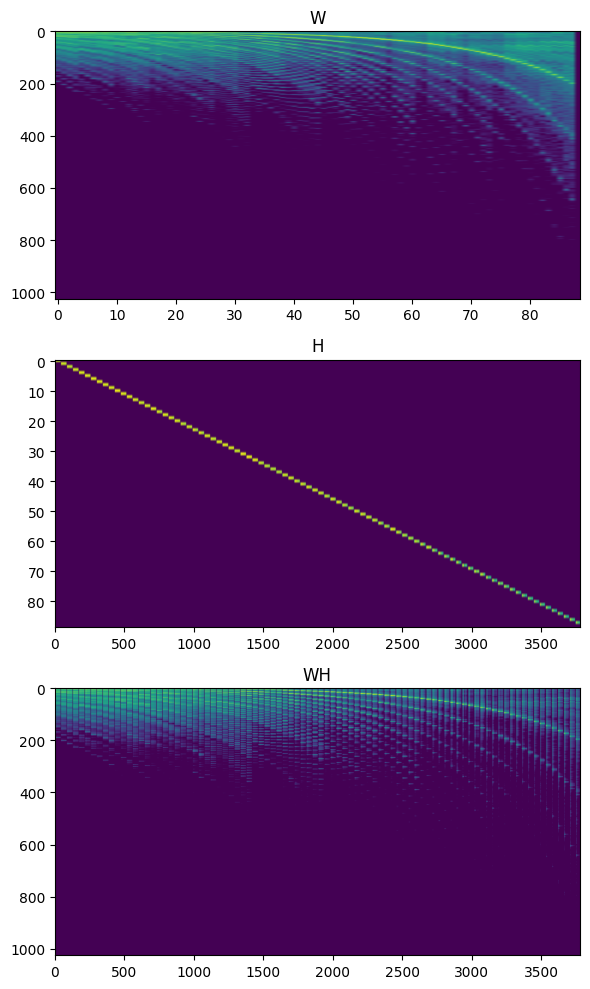

  5%|▌         | 5/100 [00:06<01:59,  1.25s/it]

Iteration 5 : Divergence = 191.58535506747714


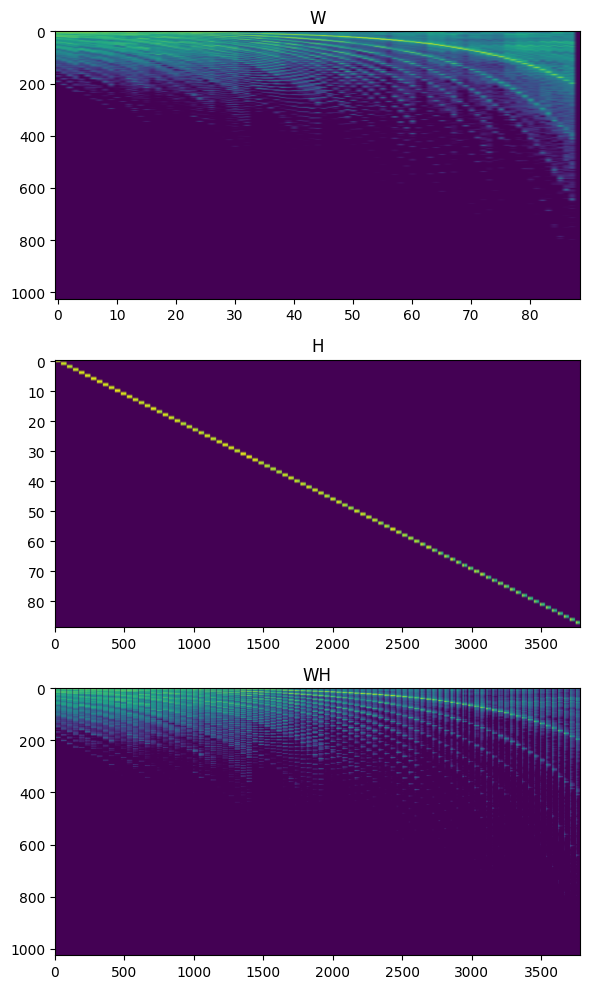

  6%|▌         | 6/100 [00:07<01:57,  1.25s/it]

Iteration 6 : Divergence = 191.58535506734225


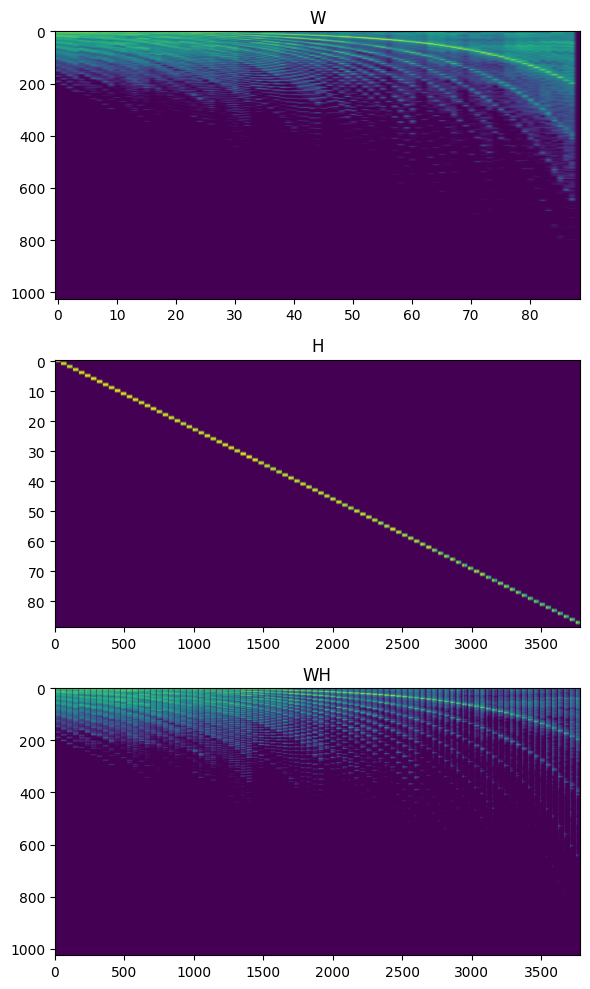

  7%|▋         | 7/100 [00:08<01:55,  1.24s/it]

Iteration 7 : Divergence = 191.58535506734012


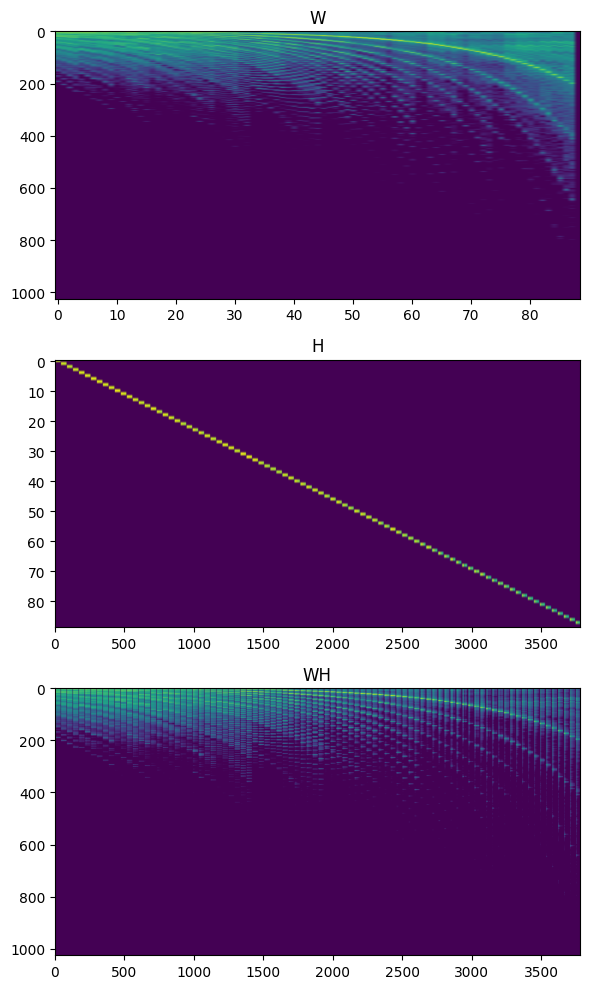

  8%|▊         | 8/100 [00:09<01:54,  1.25s/it]

Iteration 8 : Divergence = 191.5853550673403


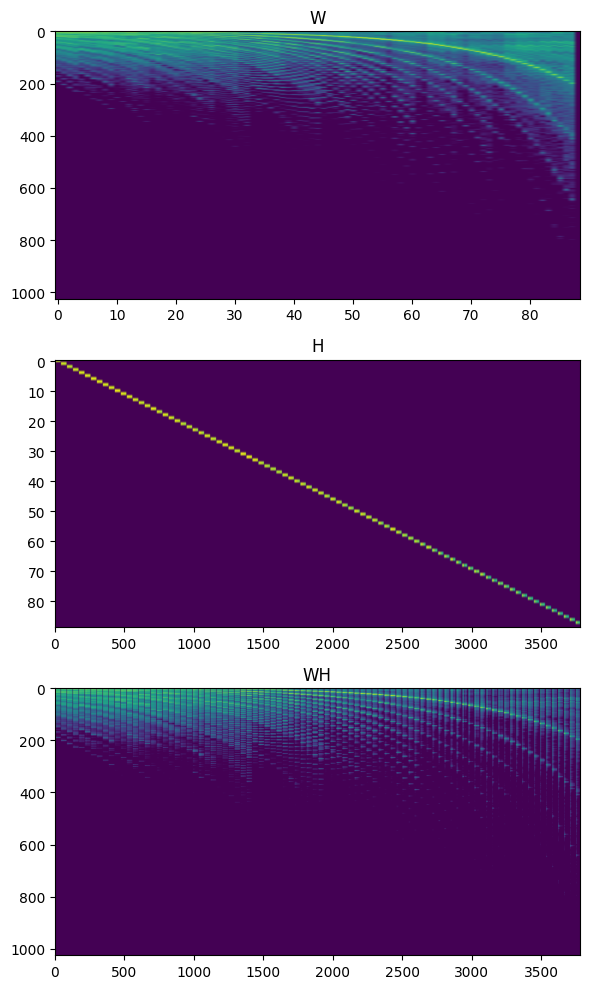

  9%|▉         | 9/100 [00:11<01:59,  1.31s/it]

Iteration 9 : Divergence = 191.58535506734012


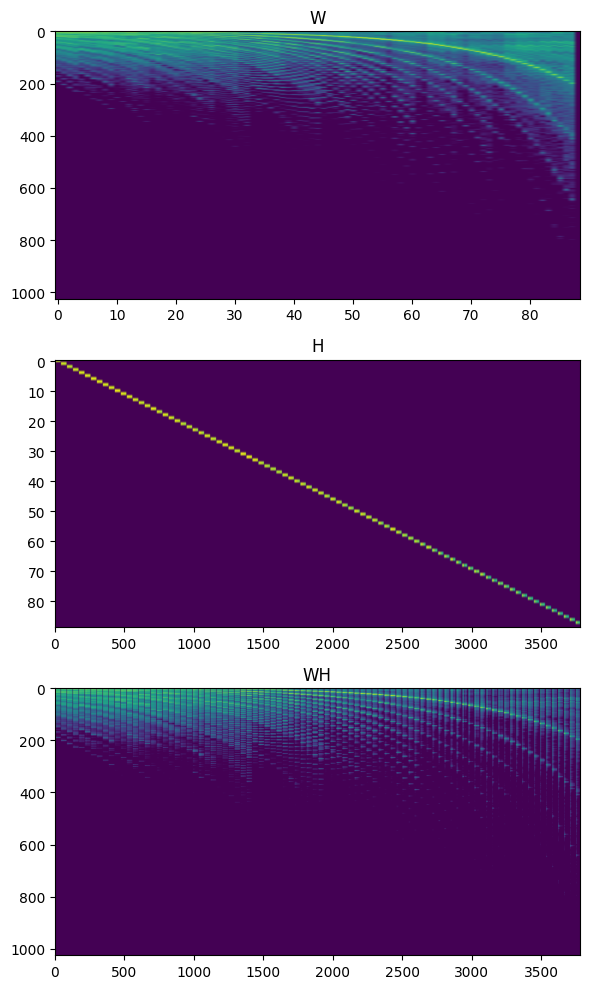

 10%|█         | 10/100 [00:12<01:56,  1.29s/it]

Iteration 10 : Divergence = 191.58535506734


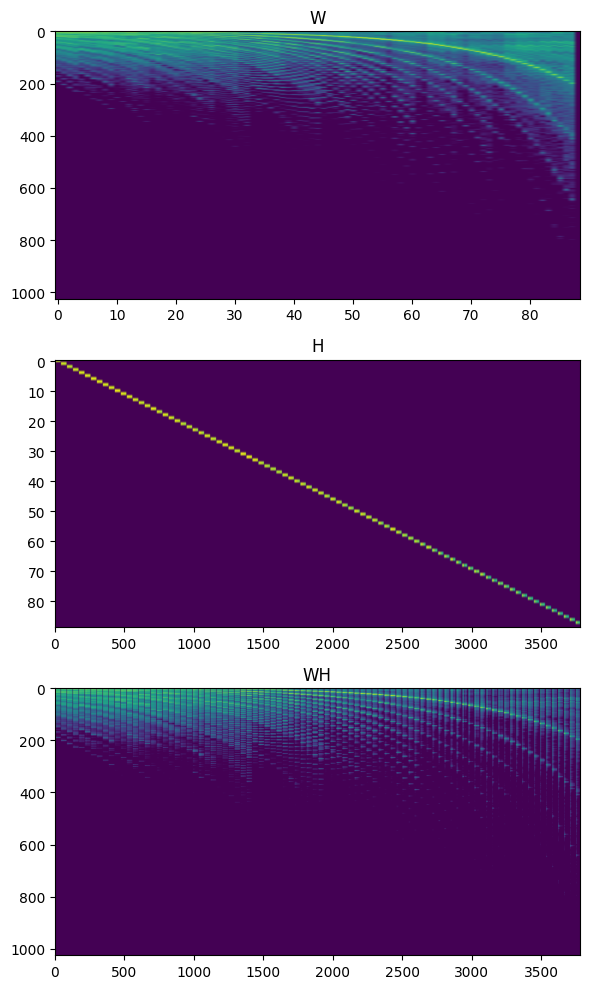

 11%|█         | 11/100 [00:13<01:53,  1.28s/it]

Iteration 11 : Divergence = 191.58535506734003


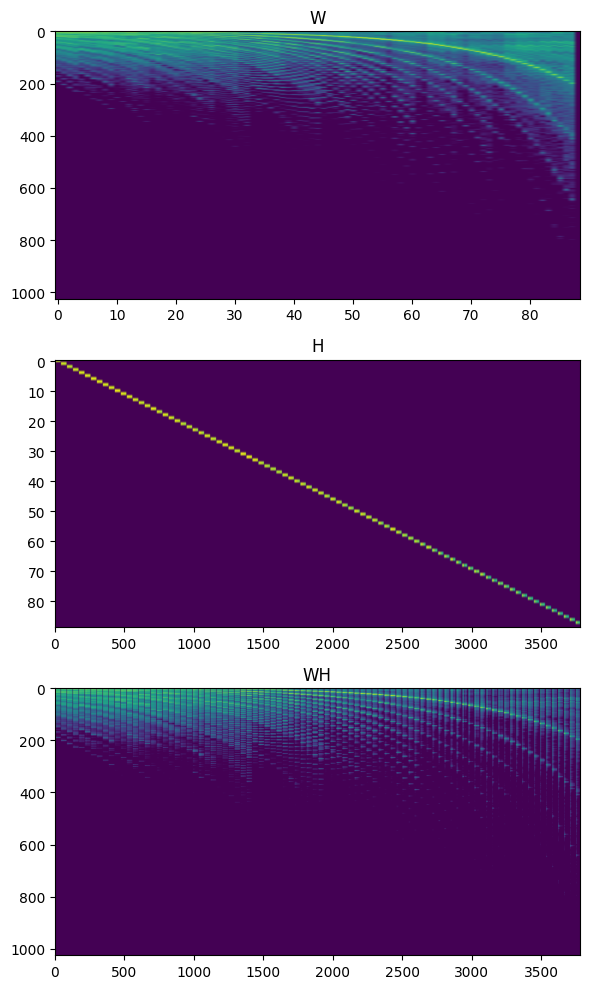

 12%|█▏        | 12/100 [00:15<01:51,  1.27s/it]

Iteration 12 : Divergence = 191.58535506734006


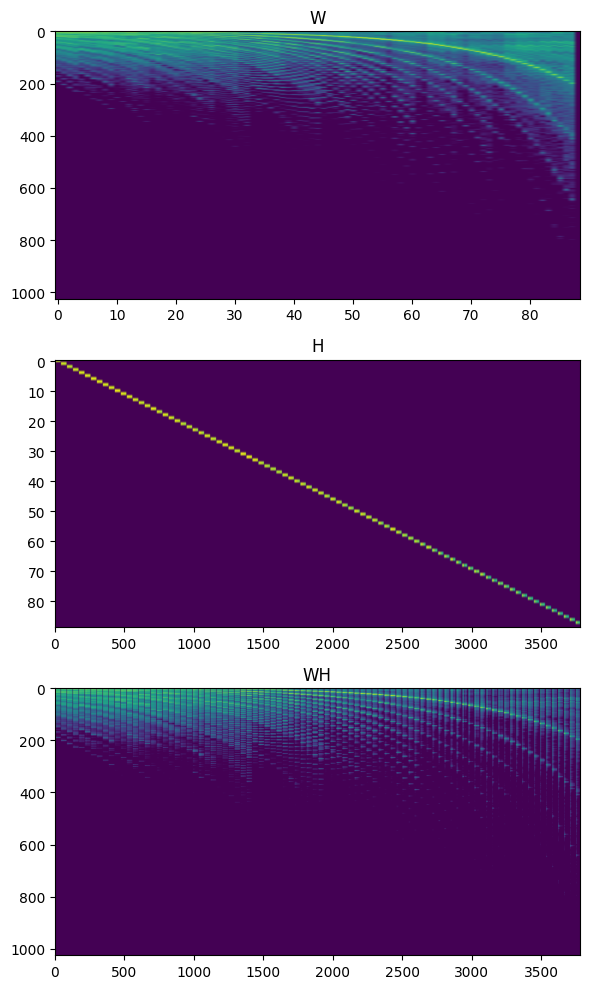

 13%|█▎        | 13/100 [00:16<01:49,  1.26s/it]

Iteration 13 : Divergence = 191.58535506734003


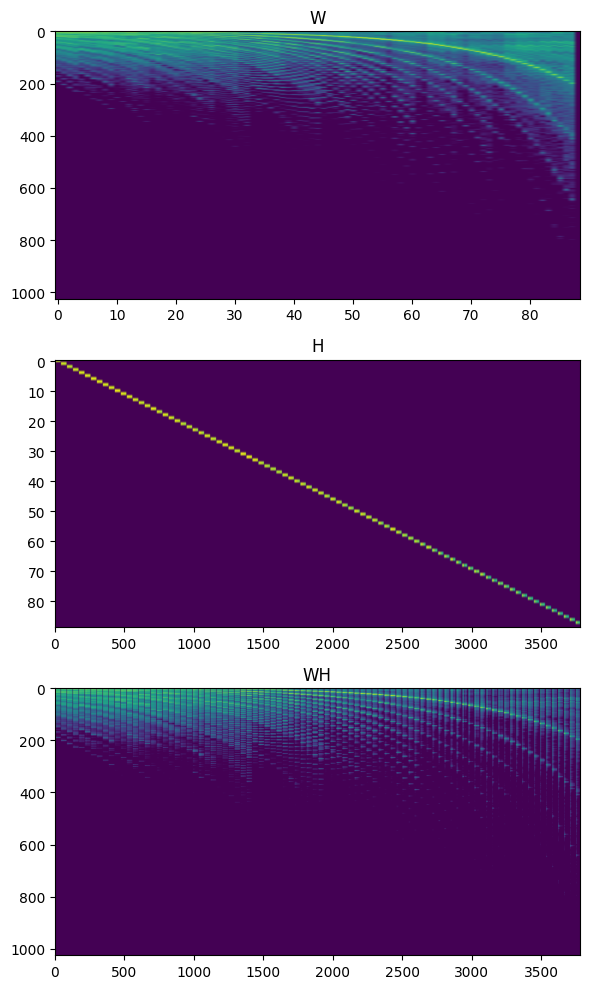

 14%|█▍        | 14/100 [00:17<01:48,  1.26s/it]

Iteration 14 : Divergence = 191.58535506734003


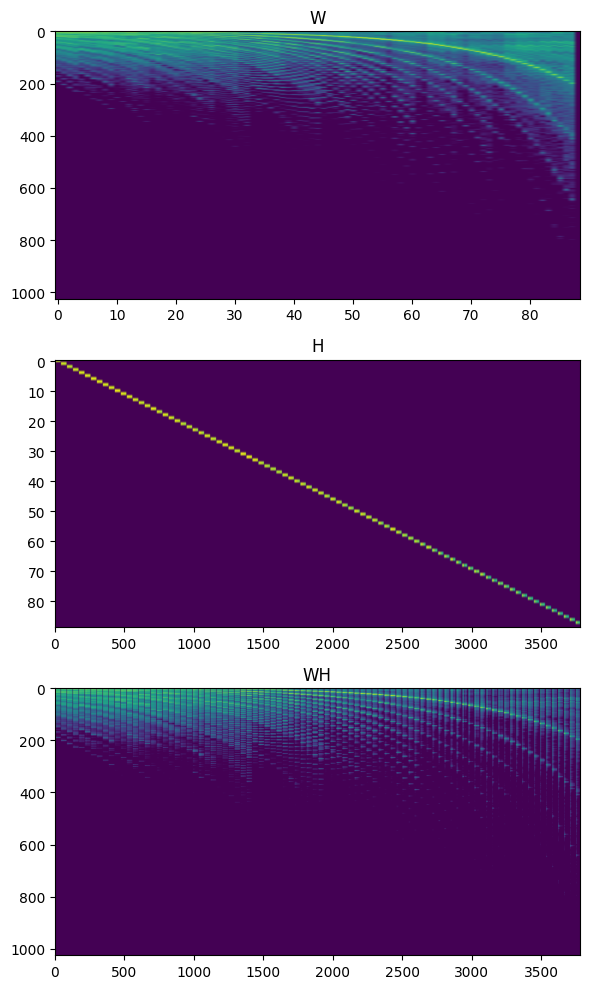

 15%|█▌        | 15/100 [00:18<01:47,  1.26s/it]

Iteration 15 : Divergence = 191.58535506734


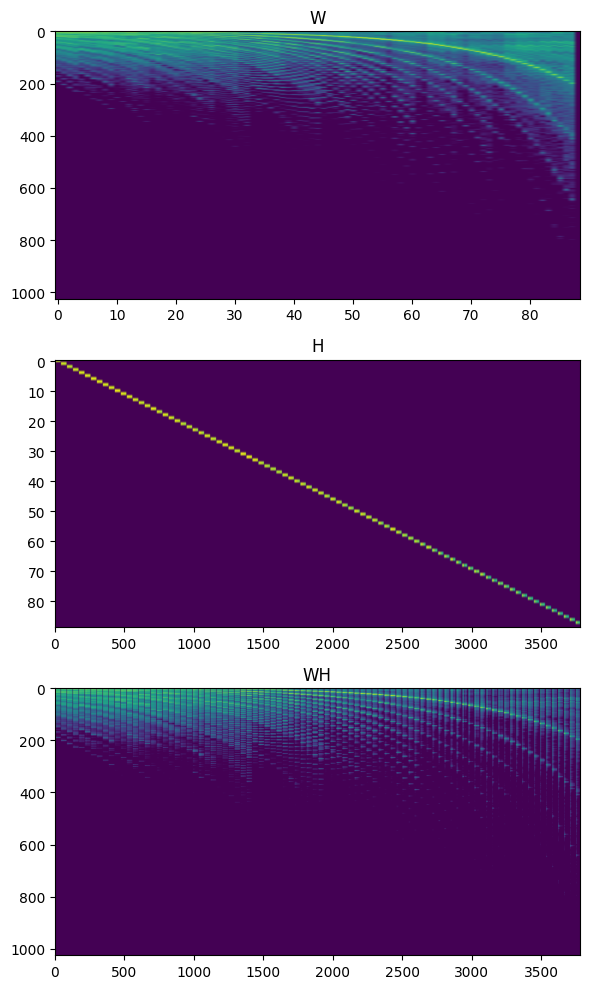

 16%|█▌        | 16/100 [00:20<01:45,  1.26s/it]

Iteration 16 : Divergence = 191.58535506734


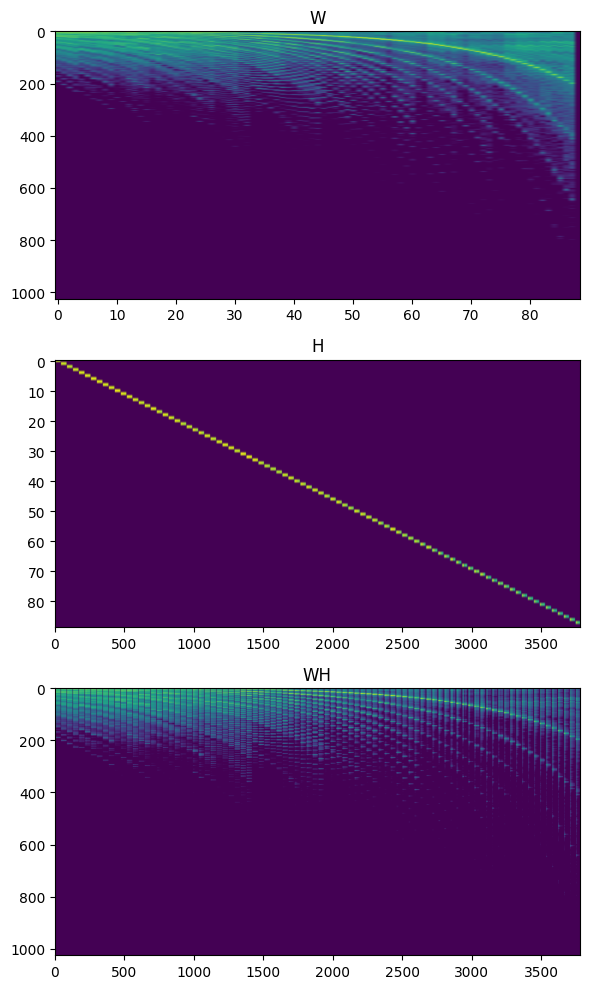

 17%|█▋        | 17/100 [00:21<01:44,  1.26s/it]

Iteration 17 : Divergence = 191.58535506734003


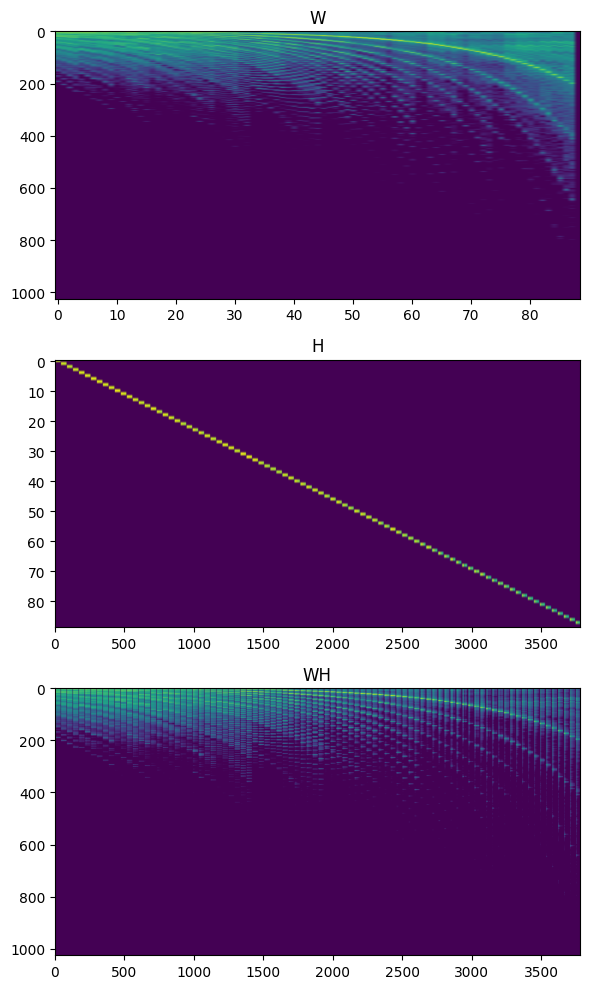

 18%|█▊        | 18/100 [00:22<01:47,  1.31s/it]

Iteration 18 : Divergence = 191.58535506734003


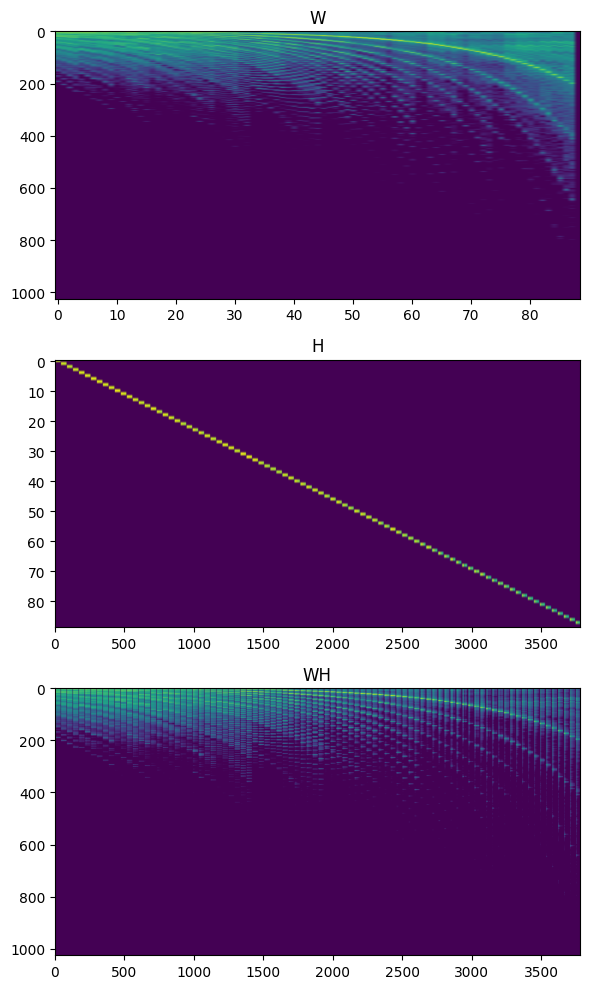

 19%|█▉        | 19/100 [00:24<01:47,  1.32s/it]

Iteration 19 : Divergence = 191.58535506734003


 19%|█▉        | 19/100 [00:25<01:48,  1.34s/it]


KeyboardInterrupt: 

In [ ]:
from tqdm import tqdm

W_ks = np.random.rand(K,S)
H_sn = piano_roll

beta = 2
for iter in tqdm(np.arange(100)):
    H_sn = H_sn * (W_ks.T @ (V*(W_ks@H_sn)**(beta-2)) / (W_ks.T @ (W_ks@H_sn)**(beta-1)+epsilon))
    W_ks = W_ks * (((V*(W_ks@H_sn)**(beta-2)) @ H_sn.T) / (((W_ks@H_sn)**(beta-1))@H_sn.T+epsilon))

    if iter % 10 == 0:
        print(f"Iteration {iter} : Divergence = {divergence(V,W_ks,H_sn,beta)}")

        # if subplot is needed
        fig, axes = plt.subplots(3, 1, figsize=(6, 10))  # Adjust figure size if needed

        axes[0].imshow(librosa.amplitude_to_db(W_ks), aspect='auto')
        axes[0].set_title('W')

        axes[1].imshow(librosa.amplitude_to_db(H_sn), aspect='auto')
        axes[1].set_title('H')

        axes[2].imshow(librosa.amplitude_to_db(W_ks @ H_sn), aspect='auto')
        axes[2].set_title('WH')

        # Adjust layout to prevent overlapping
        plt.tight_layout()
        plt.show()

In [48]:
import pretty_midi
import random

def create_random_piano_midi(output_file: str, num_notes: int = 10):
    # Create a PrettyMIDI object
    midi = pretty_midi.PrettyMIDI()
    
    # Create a piano instrument
    piano = pretty_midi.Instrument(program=pretty_midi.instrument_name_to_program("Acoustic Grand Piano"))
    
    start_time = 0.0
    for _ in range(num_notes):
        # Choose a random MIDI note number (within the range of a piano)
        note_number = random.randint(36, 84)  # From C2 to C6
        
        # Choose a random duration between 0.2 and 1.0 seconds
        duration = random.uniform(0.2, 1.0)
        
        # Choose a random velocity (soft to strong)
        velocity = random.randint(50, 100)
        
        # Create a note
        note = pretty_midi.Note(velocity=velocity, pitch=note_number, start=start_time, end=start_time + duration)
        
        # Add note to the piano instrument
        piano.notes.append(note)
        
        # Increment start time for next note
        start_time += duration + random.uniform(0.1, 0.3)  # Adding some spacing
    
    # Add instrument to the PrettyMIDI object
    midi.instruments.append(piano)
    
    # Write the MIDI file
    midi.write(output_file)
    print(f"MIDI file saved to {output_file}")

# Generate a random MIDI file
create_random_piano_midi("random_piano_composition.mid")

MIDI file saved to random_piano_composition.mid


(89, 649)


(1025, 649)


Text(0.5, 1.0, 'Piano Roll Aligned with STFT')

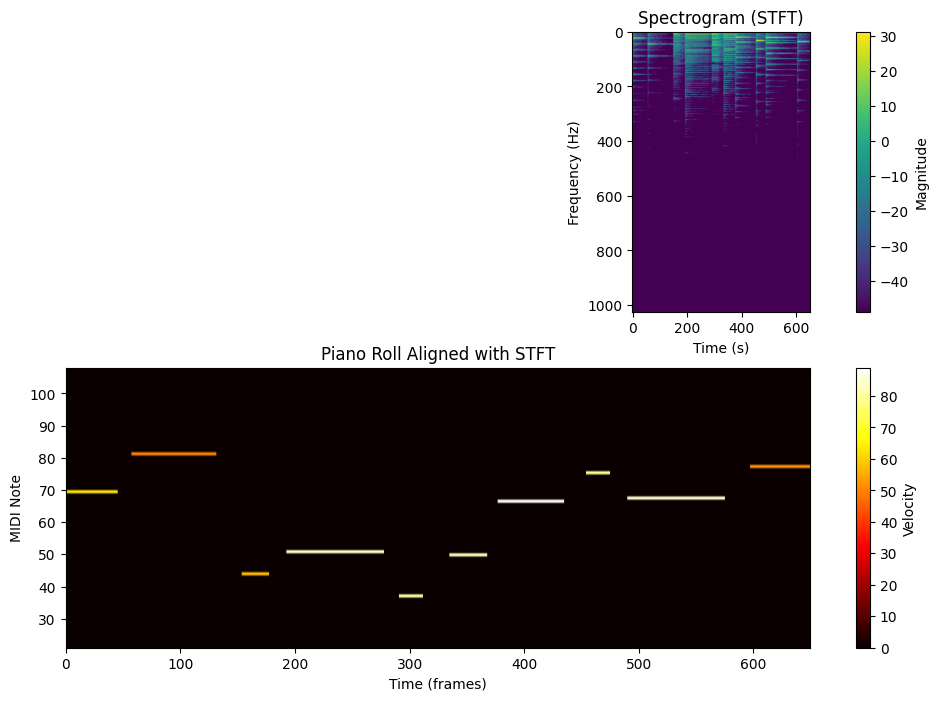

In [12]:
import IPython

midi_file = "random_piano_composition.mid"
midi = pretty_midi.PrettyMIDI(midi_file)
piano_roll = midi.get_piano_roll(fs=fs // 512)  # Match time resolution with STFT hop size
piano_roll = piano_roll[21:110, :]  # Exclude notes below MIDI note 21 (A0)
print(piano_roll.shape)

x, fs = librosa.load("random_piano_composition.wav", sr=None)
IPython.display.display(IPython.display.Audio(x, rate=fs))
X = librosa.stft(x, n_fft=2048, hop_length=512)
Zxx = np.abs(X[:,:piano_roll.shape[1]])
print(Zxx.shape)
    
# Plot STFT and piano roll
plt.figure(figsize=(12, 8))

# Plot STFT
plt.subplot(2, 1, 1)
plt.imshow(librosa.amplitude_to_db(Zxx))
plt.colorbar(label='Magnitude')
plt.xlabel("Time (s)")
plt.ylabel("Frequency (Hz)")
plt.title("Spectrogram (STFT)")

# Plot piano roll
plt.subplot(2, 1, 2)
plt.imshow(piano_roll, aspect='auto', cmap='hot', origin='lower', extent=[0, piano_roll.shape[1], 21, 108])
plt.colorbar(label='Velocity')
plt.xlabel("Time (frames)")
plt.ylabel("MIDI Note")
plt.title("Piano Roll Aligned with STFT")

S = 89 : Number of notes


  0%|          | 0/100 [00:00<?, ?it/s]

Iteration 0 : Divergence = 139.95013066441757


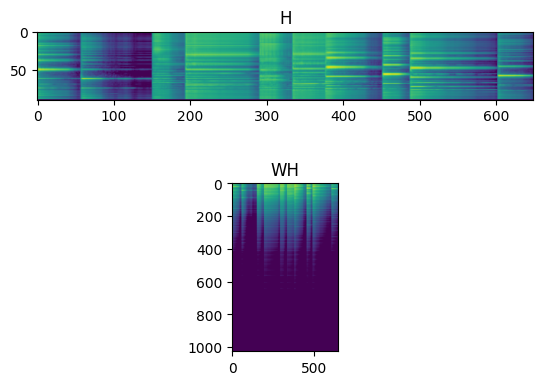

 20%|██        | 20/100 [00:00<00:01, 45.64it/s]

Iteration 20 : Divergence = 31.219945248497698


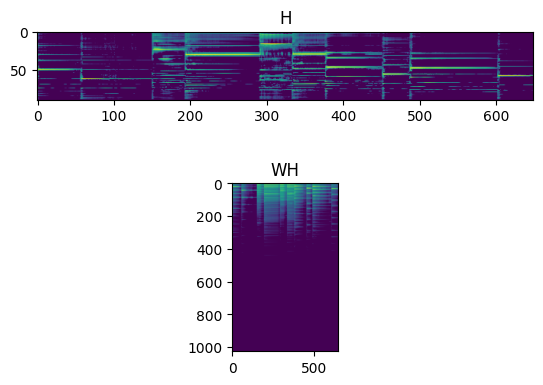

 36%|███▌      | 36/100 [00:01<00:01, 38.43it/s]

Iteration 40 : Divergence = 27.642454937870575


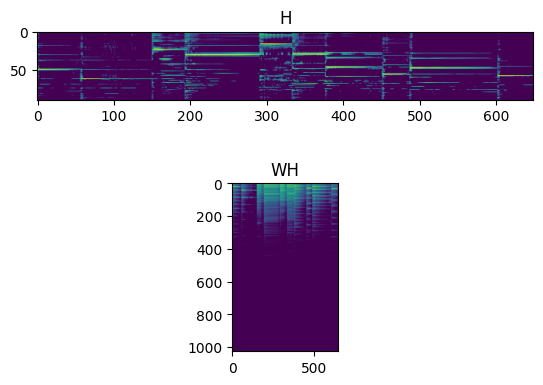

 53%|█████▎    | 53/100 [00:01<00:01, 38.73it/s]

Iteration 60 : Divergence = 26.8522991505699


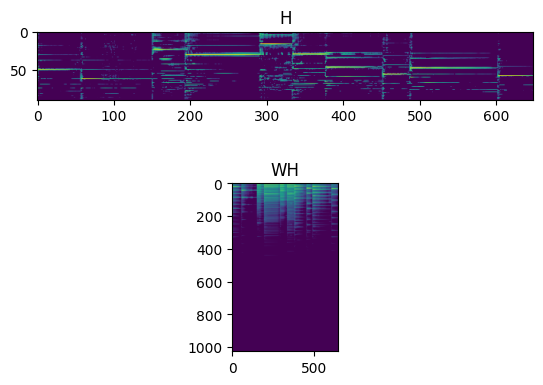

 80%|████████  | 80/100 [00:02<00:00, 48.00it/s]

Iteration 80 : Divergence = 26.561662269671277


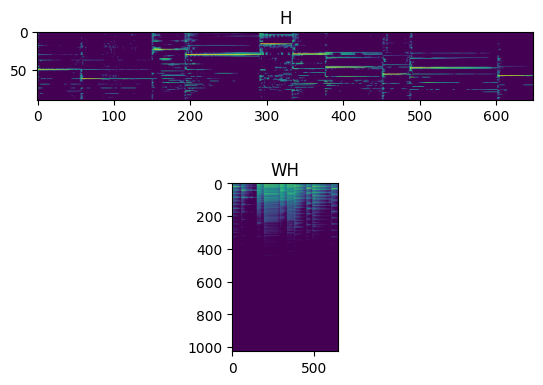

100%|██████████| 100/100 [00:02<00:00, 36.26it/s]


In [13]:
epsilon = 1e-10 # error to introduce
V = Zxx + epsilon
K, N = np.shape(V)
S = 89 
print(f"S = {S} : Number of notes")

# W_ks = np.random.rand(K,S)
H_sn = np.ones((S,N))

beta = 2
for iter in tqdm(np.arange(100)):
    H_sn = H_sn * (W_ks.T @ (V*(W_ks@H_sn)**(beta-2)) / (W_ks.T @ (W_ks@H_sn)**(beta-1)+epsilon))
    
    if iter % 20 == 0:
        print(f"Iteration {iter} : Divergence = {divergence(V,W_ks,H_sn,beta)}")

        # if subplot is needed
        plt.subplot(2,1,1)
        plt.imshow(librosa.amplitude_to_db(H_sn))
        plt.title('H')
        plt.subplot(2,1,2)
        plt.imshow(librosa.amplitude_to_db(W_ks@H_sn))
        plt.title('WH')
        plt.show()

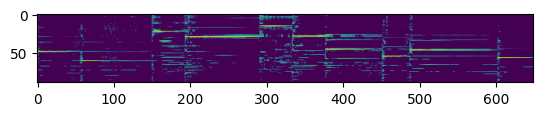

In [14]:
plt.imshow(librosa.amplitude_to_db(H_sn))
plt.show()